In [1]:
import torch
from torchvision import datasets
import matplotlib.pyplot as plt
%matplotlib inline


In [8]:
data_folder = '~/data/MNIST'
train = datasets.MNIST(data_folder, train=True, download=True)
test = datasets.MNIST(data_folder, train=False, download=True)
print(f'train: {len(train)}')
print(f'test: {len(test)}')

x_train = train.data[:1000]
y_train = train.targets[:1000]
x_test = test.data[:500]
y_test = test.targets[:500]
print(f'reduce training sample : {len(x_train)}')
print(f'reduce test sample : {len(x_test)}')

train: 60000
test: 10000
reduce training sample : 1000
reduce test sample : 500


In [15]:
print (f'train image: {x_train.shape}')
print (f'train label: {y_train.shape}')
print (f'test image: {x_test.shape}')
print (f'test label: {y_test.shape}')
print("========= Coverting Each Image to Singel Dimension or Vector ========= ")
x_train = x_train.view(x_train.size(0), -1).float()
x_test  = x_test.view(x_test.size(0), -1).float()

print(f'Train images: {x_train.shape}')
print(f'Test images: {x_test.shape}')

train image: torch.Size([1000, 784])
train label: torch.Size([1000])
test image: torch.Size([500, 784])
test label: torch.Size([500])
========= Coverting Each Image to Singel Dimension or Vector ========= 
Train images: torch.Size([1000, 784])
Test images: torch.Size([500, 784])


In [29]:
class KNN:
  def __init__(self, k=3):
    self.k = k

  def train(self, x_train, y_train):
    self.x_train = x_train
    self.y_train = y_train

  def predict(self, x_test):
    if x_test.dim() == 1:
      x_test = x_test.unsqueeze(0)

    preds = []
    for x in x_test:
        distances = torch.sum(torch.abs(self.x_train-x),dim=1)
        knn_idx = distances.topk(self.k,largest=False).indices
        knn_labels = self.y_train[knn_idx]
        pred = torch.mode(knn_labels).values.item()
        preds.append(pred)
    preds = torch.tensor(preds)
    return preds

In [30]:
model = KNN(3)
model.train(x_train,y_train)
results = model.predict(x_test)
accuracy = (y_test == results).float().mean().item()*100;
print(f'Using Training Samples = {x_train.size(0)} and Testing Samples = {x_test.size(0)}')
print(f'Accuracy = {accuracy:.2f}%')

Using Training Samples = 1000 and Testing Samples = 500
Accuracy = 80.80%


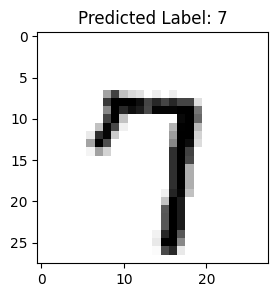

In [31]:
rand_image = x_test[torch.randint(0, len(x_test), ())]
result = model.predict(rand_image)
plt.figure(figsize=(3, 3))
plt.title(f'Predicted Label: {result.item()}')
plt.imshow(rand_image.view(28, 28), cmap='gray_r')
plt.show()